# Sphere — Section 6.1

Learn an invariant encoder, a discrete-time quotient map, and an orbit decoder jointly with EMLP/Objax. Compare the learned and analytical dynamics using CMGDB Morse graphs and reconstructed original-space Conley indices.

Run the cells in order. The training cell loads the saved fit by default; set `retrain=True` to train with the displayed configuration.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "upstream.json").is_file())
sys.path.insert(0, str(ROOT / "src"))
from notebook_support import workspace
from quotient_fitting import fit_quotient
from example_plots import paper_reference, show_analytical
from quotient_notebook import show_quotient_fit
from quotient_domain_notebook import quotient_domain_study, show_domain_comparison
ROOT, EXAMPLES, DATA = workspace()
from sphere_comparison import show_sphere_comparison


Bernardo's code: 21acca6; numerical input checksums verified.


## System and analytical quotient

For p = (x, y, z) on S², the ODE is

$$
\dot p=0.6\,e_3\times p+z(0.4^2-z^2)(e_3-zp).
$$

The analytical quotient encoder is q(p) = z. Its flow satisfies

$$
\dot z=z(0.4^2-z^2)(1-z^2),\qquad \bar F(z)=h_{10}(z).
$$

The sphere illustration retains the rotation. For learning we remove that known rotation, giving an O(2)-equivariant co-rotating system with the same height equation. The reference height plot shows h₃; CMGDB uses h₁₀.

In [2]:
reference = paper_reference(ROOT, EXAMPLES, DATA, "sphere")
show_analytical(reference, "sphere")

Matplotlib is building the font cache; this may take a moment.


## Joint encoder, quotient map and orbit decoder

The raw-state invariant EMLP encoder, interval map and orbit decoder are

$$
E_\theta:S^2\to[-1,1],\qquad f_\psi:[-1,1]\to[-1,1],\qquad
D_\phi(q)=\left(\sqrt{1-\widehat z_\phi(q)^2},0,\widehat z_\phi(q)\right).
$$

The decoder chooses longitude zero; reconstruction is up to the O(2) action.
All networks use the official EMLP/Objax implementation. The encoder's learned pole values calibrate its output to −1 and 1 during training; gradients pass through this calibration. A sampled monotonicity/range check must pass.

The interval map preserves its endpoints:

$$
f_\psi(q)=\frac{q+t_\psi(q)}{1+q\,t_\psi(q)},\qquad
 t_\psi(q)=\tanh\!\left(3\tanh\!\left(N_\psi(q)/3\right)\right).
$$

For raw-state pairs with x⁺ = F₁(x), jointly update θ, ψ and φ using

$$
L=L_{\rm rec}+L_{\rm pred}+L_{\rm con},
$$

$$
L_{\rm rec}=\mathbb E\,d_G(D_\phi(E_\theta(x)),x)^2,\quad
L_{\rm pred}=\mathbb E\,d_G(D_\phi(f_\psi(E_\theta(x))),x^+)^2,
$$

$$
L_{\rm con}=\mathbb E\,\|f_\psi(E_\theta(x))-E_\theta(x^+)\|^2.
$$

Here d_G is the minimum Euclidean distance over rotations/reflections. Reconstruction uses both members of each pair. The objective also includes cycle-consistency (weight 0.1) and latent-spread (weight 0.01) regularization. No physical height targets are supplied to the encoder. Select the checkpoint by validation loss; test trajectories and Morse graphs are excluded from selection.

**Training step: 1. CMGDB horizon: 10 learned steps.** The two settings are separate below.

The loss plot refreshes every 200 updates during training. Set `retrain=True` for a fresh run; a cached fit shows its saved curve. The orange curve uses validation data, separate from the final test set.

Training uses 4,096 independent uniform sphere points, without pole replacement. The encoder calibration evaluates the two poles without adding them as training pairs. Validation uses 512 points with pole weighting; testing uses 512 uniform sphere points.

In [3]:
fit = fit_quotient("sphere", training="joint", seed=0, joint_steps=8000,
                   train_starts=4096, training_boundary_fraction=0.0,
                   time_step=1.0, cmgdb_iterations=10, retrain=False, live=True)
# Set train_starts=16384 to use the larger uniform training set.

Loaded raw-state sphere quotient fit (seed 0).


In [4]:
show_quotient_fit(fit)

<Figure size 1200x320 with 3 Axes>

Held-out orbit RMS / state scale,Reconstruction,One step,Ten steps
Raw states,1.81%,1.05%,5.42%


## CMGDB on the learned interval

Compute the native CMGDB graphs of the fixed checkpoint's tenth iterate on several grids. Group only nearby components with their connecting cells, then recompute each grouped index and compare with the analytical five-node graph.

Cell images use sampled hulls. These numerical graph and index comparisons are not certified outer approximations or proofs about the original ODE.

**128 cells.** Bands show encoder preimages of native Morse cells, colored by aggregate. S/N are the poles, A−/A+ the attracting latitude circles, and C the repelling central circle. The interval row shows analytical height and learned quotient coordinates. Arb bounds verify local indices for the specified direction-preserving sphere lift. [Local index checks](../build/sphere-certification/local-index-argument.md).

**Approximate dynamics agreement:** at physical quotient fixed points, the largest one-step defect $\|f(E(x_*))-E(x_*)\|$ is **0.0033534** (sample interval 1). The learned lifts’ verified local indices match the analytical indices. Transfer to the physical ODE requires suitable encoder coordinates and a neighborhood-wide error bound small enough to preserve isolation along a continuation; the sampled residual does not establish these conditions. [Details](../build/conjugacy-check/claim-scope.md).

Grid,Rectangle components,Encoder-image components
128,9,9
256,8,8
512,9,9
1024,7,7



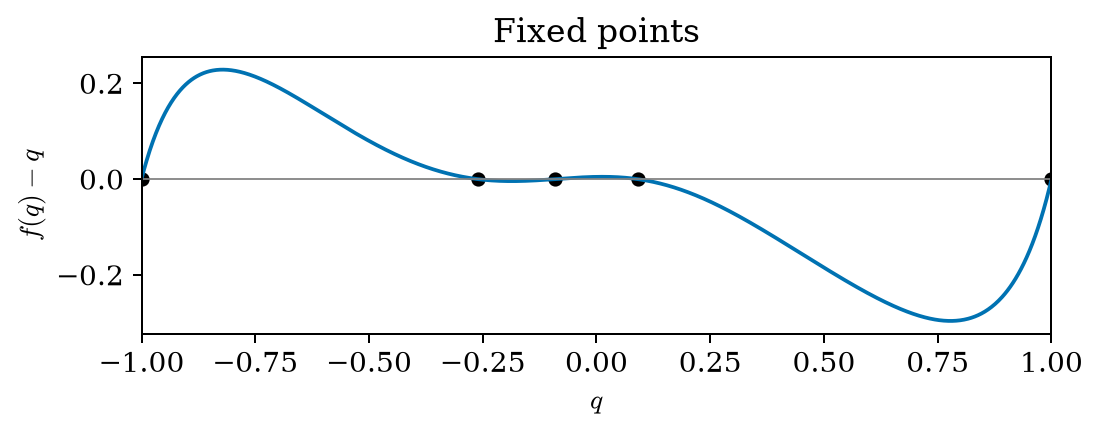

In [5]:
study = quotient_domain_study(fit, levels=(7, 8, 9, 10))
pullback = show_sphere_comparison(fit, study)
show_domain_comparison(reference, fit, study, show_graphs=False)